<a href="https://colab.research.google.com/github/wajdalkhaldi/NLP/blob/main/lab11/Lab_11_Attention_with_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [8]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [11]:
import os

dataset_path = "/content/Lab_11_QnA_Dataset_Download.csv"
if not os.path.exists(dataset_path):
    uploaded = files.upload()
    dataset_path = next(
        (name for name in uploaded if name.lower().endswith(".csv")),
        None
    )
    if dataset_path is None:
        raise FileNotFoundError("Please upload the Lab 11 Q&A CSV dataset.")

df = pd.read_csv(dataset_path)
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset (1).csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import string

# 1. Lowercase and remove punctuation
df["question"] = (
    df["question"].astype(str).str.lower()
    .str.translate(str.maketrans("", "", string.punctuation))
)

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers: encode answer_id values as consecutive class labels
y_values, answer_classes = pd.factorize(df["answer_id"])
y = y_values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [17]:
# Step 4 — Build an RNN with attention

class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Embedding: convert word numbers into vectors
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)

        # RNN: process the sequence of words
        self.rnn = nn.RNN(16, 32, batch_first=True)

        # Attention: calculate attention score for each word
        self.att = nn.Linear(32, 1)

        # Output: predict the answer group
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):

        # Convert words into embeddings and process them using RNN
        x, _ = self.rnn(self.emb(x))

        # Calculate attention weights
        weights = torch.softmax(self.att(x), dim=1)

        # Apply attention weights and combine information
        context = (x * weights).sum(1)

        # Predict the answer
        return self.fc(context), weights.squeeze(-1)


# Create the model
model = RNN()

print("RNN model created successfully!")

RNN model created successfully!


## Step 5 — Train the model
The model learns which answer belongs to each question.

In [18]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")
print("Final training loss:", round(loss.item(), 4))

Training finished!
Final training loss: 0.0967


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

Question 1: do you get hurt
Highest attention: 'you' (weight = 0.8050)



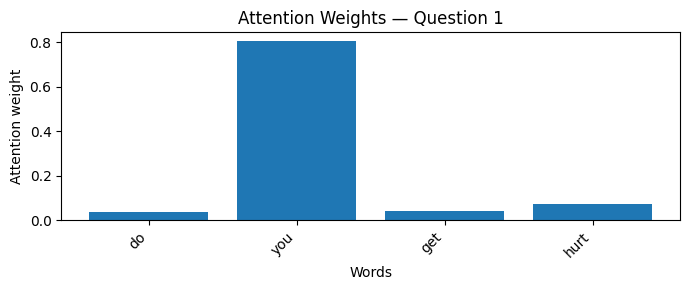

Question 2: do you have fingers
Highest attention: 'you' (weight = 0.8363)



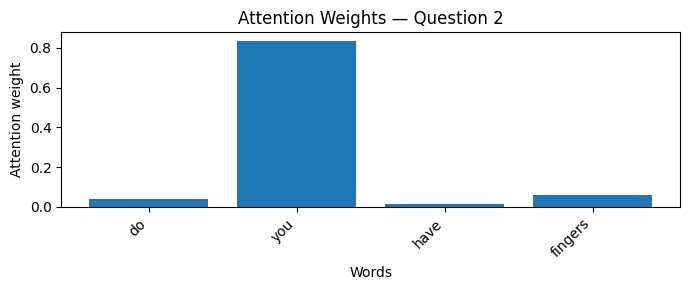

Question 3: do you ever breathe
Highest attention: 'you' (weight = 0.8154)



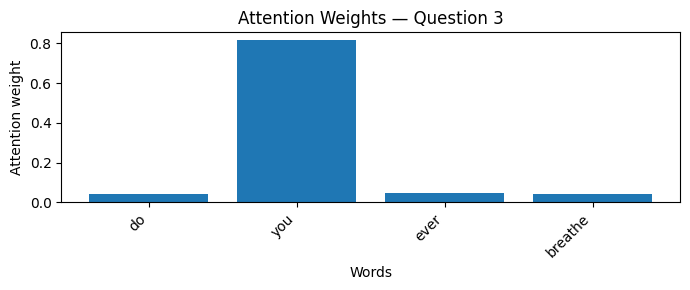

In [19]:
# Visualize attention weights for three questions
model.eval()
selected_indices = list(range(min(3, len(df))))

for question_index in selected_indices:
    question = df["question"].iloc[question_index]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[question_index:question_index + 1])

    word_weights = weights[0, :len(words)].tolist()
    if words:
        highest_index = max(range(len(word_weights)), key=word_weights.__getitem__)
        print(
            f"Question {question_index + 1}: {question}\n"
            f"Highest attention: '{words[highest_index]}' "
            f"(weight = {word_weights[highest_index]:.4f})\n"
        )

        plt.figure(figsize=(max(7, len(words) * 0.65), 3))
        plt.bar(words, word_weights)
        plt.title(f"Attention Weights — Question {question_index + 1}")
        plt.xlabel("Words")
        plt.ylabel("Attention weight")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

**Observation / Answer:**
The words with the highest attention weights are the words the model relied on most when forming its prediction.

They may represent important information such as the main topic, an entity, or a question word.

If the highest-weight words match the key information needed to understand the question, this suggests that attention is highlighting useful parts of the input.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 74: what do you do
Predicted answer group: 5
Highest attention: 'what' (weight = 0.6916)



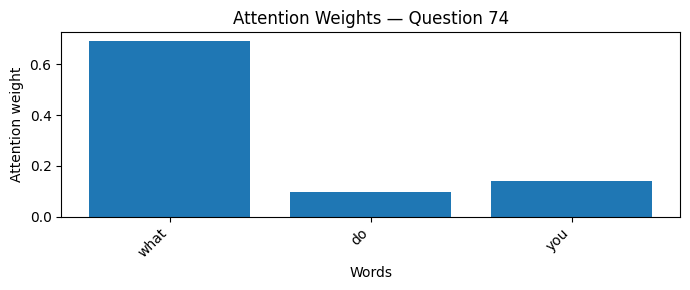

Question 115: who are you
Predicted answer group: 3
Highest attention: 'who' (weight = 0.8992)



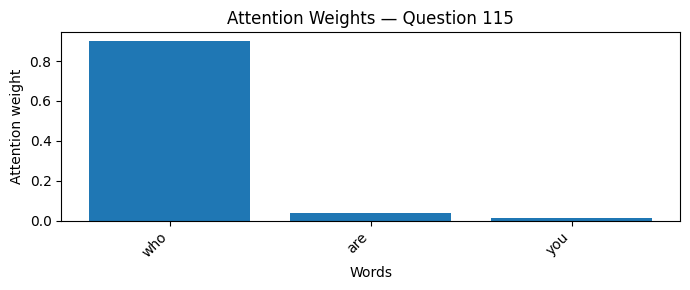

Selected pair similarity (Jaccard overlap): 1.000
The pair was selected automatically based on shared non-stopwords.
Compare the two plots: similar high-weight content words suggest that the model attends to shared information; different high-weight words suggest that it uses wording-specific clues. Attention can vary even for questions with similar meanings.


In [22]:
# Select two questions with similar wording but different full text.
# The pair is chosen by the largest Jaccard overlap of non-stopwords.
stop_words = {
    "a", "an", "the", "is", "are", "was", "were", "do", "does", "did",
    "what", "when", "where", "who", "why", "how", "which", "to", "of",
    "in", "on", "for", "and", "or", "with", "at", "by", "from", "it"
}

question_tokens = [
    [word for word in question.split() if word not in stop_words]
    for question in df["question"]
]

best_pair = None
best_similarity = -1

for i in range(len(question_tokens)):
    for j in range(i + 1, len(question_tokens)):
        words_i = set(question_tokens[i])
        words_j = set(question_tokens[j])
        union = words_i | words_j
        if not union:
            continue
        similarity = len(words_i & words_j) / len(union)

        # Prefer different answer groups when similarity is tied.
        tie_break = (df["answer_id"].iloc[i] != df["answer_id"].iloc[j])
        if (similarity > best_similarity or
            (similarity == best_similarity and tie_break)):
            best_similarity = similarity
            best_pair = (i, j)

if best_pair is None:
    raise ValueError("The dataset needs at least two questions with non-empty content.")

model.eval()
pair_indices = list(best_pair)

for question_index in pair_indices:
    question = df["question"].iloc[question_index]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[question_index:question_index + 1])

    word_weights = weights[0, :len(words)].tolist()
    predicted_answer_id = answer_classes[prediction.argmax(dim=1).item()]

    if words:
        highest_index = max(range(len(word_weights)), key=word_weights.__getitem__)
        print(f"Question {question_index + 1}: {question}")
        print(f"Predicted answer group: {predicted_answer_id}")
        print(
            f"Highest attention: '{words[highest_index]}' "
            f"(weight = {word_weights[highest_index]:.4f})\n"
        )

        plt.figure(figsize=(max(7, len(words) * 0.65), 3))
        plt.bar(words, word_weights)
        plt.title(f"Attention Weights — Question {question_index + 1}")
        plt.xlabel("Words")
        plt.ylabel("Attention weight")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

i, j = pair_indices
print(f"Selected pair similarity (Jaccard overlap): {best_similarity:.3f}")
print("The pair was selected automatically based on shared non-stopwords.")
print(
    "Compare the two plots: similar high-weight content words suggest that "
    "the model attends to shared information; different high-weight words "
    "suggest that it uses wording-specific clues. Attention can vary even "
    "for questions with similar meanings."
)